# 11 · Operator commands with a fine-tuned Transformer (DistilBERT)

**Phase 6 · NLP + Transformers.** Notebook 10 showed the limit of word counting: on *new phrasings*
(test templates never seen in training) TF-IDF understands about 7 messages in 10, and it maps
"order me a pizza" to a warehouse action. Here we fine-tune a **pretrained Transformer**.

**Transformer in three sentences.** A Transformer reads the whole message at once; with
*self-attention* every word looks at every other word to build a meaning that depends on context
("stop" next to "R-12" vs "stop" in "where is the stop"). **Pretraining** on large amounts of English
already taught it that "halt", "stop" and "freeze" are close. **Fine-tuning** adds two small output
layers and trains the whole network briefly on our commands.

**Our model:** one DistilBERT encoder (66 M parameters; Sanh et al., 2019) with two heads:

| Head | Reads | Predicts |
|---|---|---|
| intent | the [CLS] vector (summary of the message) | one of 17 intents, with a confidence |
| tags | one vector per word | B-/I-/O tag per word (B-ROBOT, I-AISLE, ...) → entity spans |

Same data, splits and scores as notebook 10 (honest validation: held-out templates). Trained on a
laptop CPU (no GPU needed: messages are short).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from ai.nlp.commands import INTENTS, honest_validation, load_commands  # noqa: E402
from ai.nlp.evaluation import evaluate, noisy, summary  # noqa: E402
from ai.nlp.intent_parser import RuleParser, TfidfParser  # noqa: E402
from ai.transformers.intent_transformer import TransformerParser, encode  # noqa: E402

MODELS = ROOT / "models"
torch.manual_seed(42)
torch.set_num_threads(4)
df = load_commands()
df["split2"] = honest_validation(df)  # same split as notebook 10
train, val, test = (df[df["split2"] == s] for s in ("train", "validation", "test"))
print({s: len(p) for s, p in [("train", train), ("validation", val), ("test", test)]}, "| torch", torch.__version__)

{'train': 3535, 'validation': 796, 'test': 1130} | torch 2.14.1+cpu


## 1. How DistilBERT sees a message

Text is split into **sub-word pieces** from a 30,522-piece vocabulary: common words stay whole,
rare words, typos and IDs are cut into known fragments. That is why typos do not break it:
"critiacl" becomes pieces it has seen. Each word's tag is read from its first piece.

In [2]:
parser = TransformerParser.from_pretrained_base()
example = "please what should happen when a robot's battery is critiacl"
enc = encode(parser.tokenizer, [example])
pieces = parser.tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
print(pieces)
print(f"{sum(p.numel() for p in parser.model.parameters()) / 1e6:.1f} M parameters")

H:\ai-warehouse-platform\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1478.88it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['[CLS]', 'please', 'what', 'should', 'happen', 'when', 'a', 'robot', "'", 's', 'battery', 'is', 'cr', '##itia', '##cl', '[SEP]']
66.4 M parameters


## 2. Fine-tuning

AdamW (learning rate 5e-5, linear warm-up and decay), batches of 32, loss = intent cross-entropy +
tag cross-entropy. After each epoch the **exact tool-call rate on the honest validation split** is
measured; training stops when it no longer improves and the best epoch is kept. About 10-20 min per
epoch on a laptop CPU.

In [3]:
def validate() -> float:
    return evaluate(None, val, parse_many=parser.parse_many)["exact_tool_call"]


start = time.time()
history = parser.fit((list(train["text"]), list(train["intent"]), list(train["bio_tags"])), validate,
                     epochs=5, batch=32, lr=5e-5, patience=2)  # fmt: skip
history = pd.DataFrame(history)
train_minutes = (time.time() - start) / 60
print(f"trained in {train_minutes:.0f} min")
history

epoch 1: loss 2.4994  validation 0.6508  (352 s)


epoch 2: loss 0.0575  validation 0.7085  (356 s)


epoch 3: loss 0.0138  validation 0.7450  (347 s)


epoch 4: loss 0.0075  validation 0.7814  (368 s)


epoch 5: loss 0.0062  validation 0.7676  (334 s)


trained in 29 min


,epoch,train_loss,validation,seconds
0,1,2.499418,0.650754,351.867449
1,2,0.057519,0.708543,356.413168
2,3,0.013799,0.744975,347.386922
3,4,0.007535,0.781407,367.685738
4,5,0.006219,0.767588,333.746206


## 3. Test: Transformer vs baselines (new phrasings, never seen in training)

In [4]:
rules = RuleParser()
tfidf = TfidfParser().fit(list(train["text"]), list(train["intent"]))
noisy_test = noisy(test)
scores = {
    "Rules": evaluate(rules.parse, test),
    "TF-IDF + LR": evaluate(tfidf.parse, test),
    "DistilBERT": evaluate(None, test, parse_many=parser.parse_many),
}
noise = {
    "Rules": evaluate(rules.parse, test, noisy_test),
    "TF-IDF + LR": evaluate(tfidf.parse, test, noisy_test),
    "DistilBERT": evaluate(None, test, noisy_test, parse_many=parser.parse_many),
}
table = pd.DataFrame({k: summary(v) for k, v in scores.items()}).T
table["exact tool call (with extra noise)"] = [noise[k]["exact_tool_call"] for k in table.index]
table.round(3)

,intent_accuracy,intent_macro_F1,entity_precision,entity_recall,entity_F1,exact_tool_call,approval_correct,ms_per_message,exact tool call (with extra noise)
Rules,0.657,0.691,1.0,0.999,1.000,0.656,0.823,0.092,0.527
TF-IDF + LR,0.695,0.670,1.0,0.999,1.000,0.725,0.933,2.588,0.679
DistilBERT,0.804,0.799,1.0,0.998,0.999,0.807,0.965,17.793,0.762


In [5]:
single = time.perf_counter()
for t in test["text"].head(50):
    parser.parse(t)
ms_single = (time.perf_counter() - single) * 1000 / 50
print(f"DistilBERT on the laptop CPU: {ms_single:.0f} ms per message one at a time "
      f"({scores['DistilBERT']['ms_per_message']:.1f} ms in batches)")

DistilBERT on the laptop CPU: 46 ms per message one at a time (17.8 ms in batches)


## 4. Per intent: where the Transformer helps

In [6]:
from sklearn.metrics import f1_score

per = pd.DataFrame({
    name: f1_score(test["intent"], s["predictions"], labels=INTENTS, average=None, zero_division=0)
    for name, s in scores.items()
}, index=INTENTS).round(2)  # fmt: skip
per["gain vs TF-IDF"] = per["DistilBERT"] - per["TF-IDF + LR"]
per.sort_values("gain vs TF-IDF", ascending=False)

,Rules,TF-IDF + LR,DistilBERT,gain vs TF-IDF
out_of_scope,0.67,0.08,0.68,0.60
route_planning,0.99,0.10,0.48,0.38
investigate_delay,0.99,0.70,0.99,0.29
fleet_overview,0.64,0.43,0.68,0.25
assign_order,0.14,0.76,1.00,0.24
task_assignment,0.14,0.72,0.96,0.24
create_order,0.68,0.78,1.00,0.22
robot_status,0.35,0.82,1.00,0.18
pause_robot,0.96,0.68,0.80,0.12
pending_orders,0.64,0.77,0.88,0.11


In [7]:
bert_pred, tfidf_pred = scores["DistilBERT"]["predictions"], scores["TF-IDF + LR"]["predictions"]
cmp = test.assign(tfidf=tfidf_pred, distilbert=bert_pred)
fixed = cmp[(cmp["distilbert"] == cmp["intent"]) & (cmp["tfidf"] != cmp["intent"])]
broken = cmp[(cmp["distilbert"] != cmp["intent"]) & (cmp["tfidf"] == cmp["intent"])]
print(f"DistilBERT right where TF-IDF was wrong: {len(fixed)}; the other way round: {len(broken)}")
fixed.groupby("intent").head(1).head(8)[["text", "intent", "tfidf"]]

DistilBERT right where TF-IDF was wrong: 164; the other way round: 41


,text,intent,tfidf
35,please handle the LOW orders first,task_assignment,pending_orders
168,reroute R36 to avoid aisle 38 now,reroute_robot,close_aisle
251,"hey copilot, Unpause robot #8",resume_robot,pause_robot
264,"hey copilot, why did R8 stop asap",investigate_delay,pause_robot
275,quick one: order me a pizza?,out_of_scope,create_order
287,please show the path robot 16 would take to C-...,route_planning,assign_order
428,please Give me a fleet overview,fleet_overview,robot_status
446,is R8 charging.,robot_status,fleet_overview


In [8]:
still = cmp[cmp["distilbert"] != cmp["intent"]]
print(f"{len(still)} test messages still misunderstood; most common:")
still.groupby(["intent", "distilbert"]).size().sort_values(ascending=False).head(6).rename("messages").to_frame()

222 test messages still misunderstood; most common:


,,messages
intent,distilbert,
reroute_robot,close_aisle,41
route_planning,reroute_robot,38
open_aisle,close_aisle,25
out_of_scope,fleet_overview,24
resume_robot,pause_robot,23
knowledge_query,fleet_overview,22


## 5. Confidence: ask instead of guessing

The app does not execute a command whose intent confidence is below 0.5: it asks the operator.
How well does the confidence separate right from wrong?

In [9]:
res = scores["DistilBERT"]["results"]
conf = pd.Series([r["confidence"] for r in res])
correct = pd.Series(bert_pred) == test["intent"].reset_index(drop=True)
bins = pd.cut(conf, [0, 0.5, 0.7, 0.9, 0.99, 1.0], include_lowest=True)
calib = pd.DataFrame({"messages": correct.groupby(bins, observed=True).size(),
                      "accuracy": correct.groupby(bins, observed=True).mean().round(3)})  # fmt: skip
display(calib)
wrong = ~correct
print(f"wrong intents caught by the 0.5 threshold (copilot asks): {(wrong & (conf < 0.5)).sum()} of {wrong.sum()}; "
      f"right ones it would ask about anyway: {(correct & (conf < 0.5)).sum()}")
oos = test["intent"].reset_index(drop=True) == "out_of_scope"
print(f"out-of-scope requests recognised: {(pd.Series(bert_pred)[oos] == 'out_of_scope').mean():.0%} "
      f"(TF-IDF: {(pd.Series(tfidf_pred)[oos] == 'out_of_scope').mean():.0%})")

,messages,accuracy
"(-0.001, 0.5]",20,0.450
"(0.5, 0.7]",109,0.532
"(0.7, 0.9]",185,0.578
"(0.9, 0.99]",285,0.740
"(0.99, 1.0]",531,0.985


wrong intents caught by the 0.5 threshold (copilot asks): 11 of 222; right ones it would ask about anyway: 9
out-of-scope requests recognised: 52% (TF-IDF: 4%)


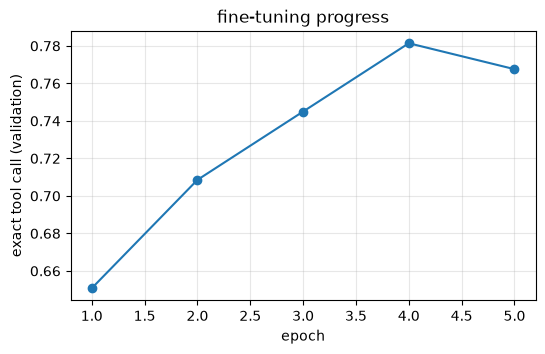

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(history["epoch"], history["validation"], marker="o")
ax.set_xlabel("epoch")
ax.set_ylabel("exact tool call (validation)")
ax.set_title("fine-tuning progress")
ax.grid(alpha=0.3)
plt.show()

## 6. Save the model and the report

In [11]:
report = {
    "model": "nlp_distilbert_v1",
    "algorithm": parser.name,
    "base_model": "distilbert-base-uncased",
    "split": {"train": len(train), "validation": len(val), "test": len(test)},
    "test": {k: summary(v) for k, v in scores.items()},
    "test_with_noise": {k: summary(v) for k, v in noise.items()},
    "per_intent_f1": per.drop(columns="gain vs TF-IDF").to_dict("index"),
    "history": history.round(4).to_dict("records"),
    "train_minutes": round(train_minutes, 1),
    "ms_per_message_single": round(ms_single, 1),
    "confidence_bins": calib.reset_index().astype(str).to_dict("records"),
}
parser.save(MODELS / "nlp_distilbert_v1", report)
print("Saved models/nlp_distilbert_v1/ (encoder, tokenizer, heads, labels, report)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.43s/it]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.45s/it]

Saved models/nlp_distilbert_v1/ (encoder, tokenizer, heads, labels, report)


## 7. Conclusions

| Test (1,130 messages from templates never seen in training) | Rules | TF-IDF + LR | **DistilBERT** |
|---|---|---|---|
| Intent accuracy | 0.657 | 0.695 | **0.804** |
| Exact tool call (the action is completely right) | 0.656 | 0.725 | **0.807** |
| Approval decision right | 0.823 | 0.933 | **0.965** |
| Exact tool call with typos / case noise | 0.527 | 0.679 | **0.762** |
| Time per message (CPU, batch / single) | 0.1 ms | 2.6 ms | 18 ms / 46 ms |

* **DistilBERT is the live parser.** +8 points of exact tool calls over TF-IDF, +8 under noise; it
  fixed 164 messages TF-IDF got wrong and broke 41. Entities were already solved (F1 ≈ 1.0 for all
  three: the BIO tag head learned the same spans the regexes find).
* **Confidence is meaningful:** above 0.99 the intent is right 98.5 % of the time (531 messages);
  below 0.9 only ~55 %. The 0.5 threshold asks instead of acting on 11 of the 222 errors.
* **Out-of-scope requests** ("order me a pizza") are recognised 52 % of the time (TF-IDF 4 %).
* **Remaining errors are mostly opposites and neighbours:** reroute → close aisle (41), route
  planning → reroute (38), open → close aisle (25), resume → pause (23). The templates for these
  pairs share almost every word, and the honest split holds whole phrasings out. In the app the
  live-warehouse checks catch the opposites (closing a closed aisle, pausing a paused robot), and
  every write action needs the operator's approval (ADR 006), so a misread message is shown, not
  executed.
* **Limits:** synthetic, template-generated English; real operators' phrasing must be collected
  and labelled before trusting these numbers. 66 M parameters, 29 min of CPU training; 250 MB on disk.
* **Next:** more paraphrases for the confused pairs (or contrastive examples), and Phase 7 RAG for
  `knowledge_query`, which is only routed here, not answered.